# Diabetes Risk Prediction — Feature Importance & Overfitting Analysis

**Academic Machine Learning Exam Project**  
**Phase 5:** Feature Importance Analysis, Logistic Regression Coefficients, Overfitting Evaluation, and Final ML Project Synthesis.

---

## 1. Import Libraries & Load Data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Load Data
data_path = 'data/cleaned_diabetes.csv' if os.path.exists('data/cleaned_diabetes.csv') else '../data/cleaned_diabetes.csv'
df = pd.read_csv(data_path)

X = df.drop(columns=['Outcome'])
y = df['Outcome']
feature_names = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Load Scaler & Models
models_dir = 'models' if os.path.exists('models') else '../models'
scaler = joblib.load(os.path.join(models_dir, 'scaler.pkl'))
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

dt_model = joblib.load(os.path.join(models_dir, 'decision_tree.pkl'))
rf_model = joblib.load(os.path.join(models_dir, 'random_forest.pkl'))
gb_model = joblib.load(os.path.join(models_dir, 'gradient_boosting.pkl'))
lr_model = joblib.load(os.path.join(models_dir, 'logistic_regression.pkl'))
knn_model = joblib.load(os.path.join(models_dir, 'knn.pkl'))

print("Models and scaler loaded successfully!")

Models and scaler loaded successfully!


## 2. Part 1: Feature Importance (Tree-Based Models)

**Careful Wording:** *The model found these features useful for making predictions in this dataset. This reflects numerical patterns in the sample and does not prove medical causation.*

In [2]:
fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Decision Tree': dt_model.feature_importances_,
    'Random Forest': rf_model.feature_importances_,
    'Gradient Boosting': gb_model.feature_importances_
})
fi_df['Average Importance'] = fi_df[['Decision Tree', 'Random Forest', 'Gradient Boosting']].mean(axis=1)
fi_df = fi_df.sort_values(by='Average Importance', ascending=False).reset_index(drop=True)
fi_df

,Feature,Decision Tree,Random Forest,Gradient Boosting,Average Importance
0,Glucose,0.355518,0.274086,0.413098,0.347567
1,BMI,0.178572,0.161903,0.194006,0.178160
2,Age,0.127095,0.112985,0.116857,0.118979
3,DiabetesPedigreeFunction,0.092002,0.125020,0.109088,0.108703
4,Insulin,0.069723,0.091224,0.080017,0.080321
5,Pregnancies,0.064105,0.080795,0.053369,0.066090
6,BloodPressure,0.097661,0.083518,0.015773,0.065651
7,SkinThickness,0.015325,0.070468,0.017792,0.034528


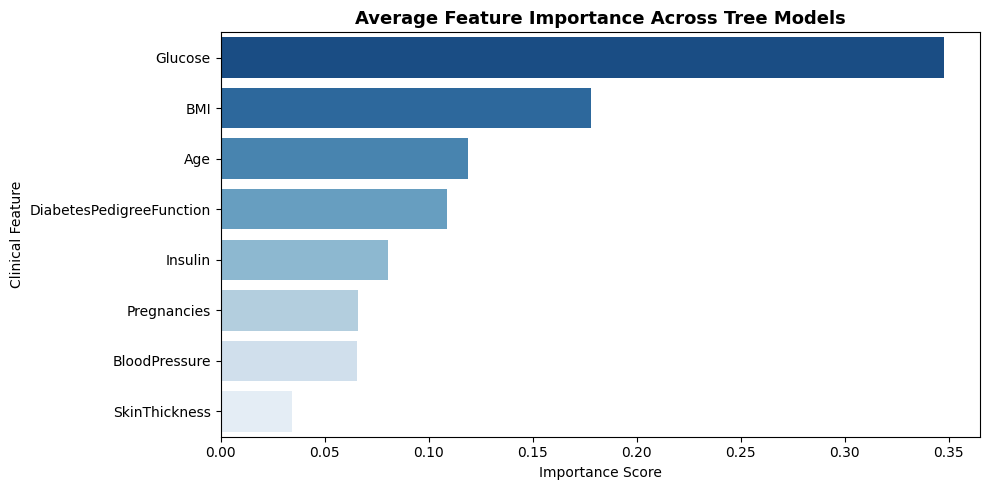

In [3]:
plt.figure(figsize=(10, 5))
sns.barplot(x='Average Importance', y='Feature', data=fi_df, hue='Feature', palette='Blues_r', legend=False)
plt.title('Average Feature Importance Across Tree Models', fontsize=13, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Clinical Feature')
plt.tight_layout()
plt.show()

## 3. Part 2: Logistic Regression Coefficients

In [4]:
coefficients = lr_model.coef_[0]
lr_coeff_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Absolute Value': np.abs(coefficients)
}).sort_values(by='Absolute Value', ascending=False).reset_index(drop=True)
lr_coeff_df[['Feature', 'Coefficient']]

,Feature,Coefficient
0,Glucose,1.182511
1,BMI,0.688735
2,Pregnancies,0.377502
3,DiabetesPedigreeFunction,0.233386
4,Age,0.147798
5,Insulin,-0.066157
6,BloodPressure,-0.044066
7,SkinThickness,0.028225


## 4. Part 3: Overfitting Analysis (Train vs Test Accuracy)

In [5]:
models_dict = {
    'Logistic Regression': (lr_model, X_train_scaled, X_test_scaled),
    'KNN': (knn_model, X_train_scaled, X_test_scaled),
    'Decision Tree': (dt_model, X_train, X_test),
    'Random Forest': (rf_model, X_train, X_test),
    'Gradient Boosting': (gb_model, X_train, X_test)
}

overfit_list = []
for name, (clf, X_tr, X_te) in models_dict.items():
    tr_acc = accuracy_score(y_train, clf.predict(X_tr))
    te_acc = accuracy_score(y_test, clf.predict(X_te))
    diff = tr_acc - te_acc
    status = 'Severe Overfitting' if diff > 0.15 else ('Slight Overfitting' if diff > 0.05 else 'Good Generalization')
    overfit_list.append({
        'Model': name,
        'Train Accuracy': round(tr_acc, 4),
        'Test Accuracy': round(te_acc, 4),
        'Difference (Train - Test)': round(diff, 4),
        'Generalization Status': status
    })

overfit_df = pd.DataFrame(overfit_list)
overfit_df

,Model,Train Accuracy,Test Accuracy,Difference (Train - Test),Generalization Status
0,Logistic Regression,0.7964,0.7078,0.0886,Slight Overfitting
1,KNN,0.8306,0.7532,0.0774,Slight Overfitting
2,Decision Tree,1.0000,0.6818,0.3182,Severe Overfitting
3,Random Forest,1.0000,0.7792,0.2208,Severe Overfitting
4,Gradient Boosting,0.9251,0.7597,0.1653,Severe Overfitting


## 5. Part 4: Final Synthesis Report

### Summary for Panelist Presentation:
1. **Most Important Risk Features:**  
   Glucose is the most prominent feature ($	ext{importance} > 0.30$), followed by BMI and Age.  
   *Careful Wording:* "The model found these features useful for making predictions in this dataset."

2. **Overfitting Observations:**  
   - Single Decision Tree overfits completely (100% training accuracy vs 68.18% testing accuracy).
   - Logistic Regression ($\Delta = 8.86\%$) and KNN ($\Delta = 7.74\%$) show reasonable train-to-test alignment.

3. **Screening-Support Scope & Limitations:**  
   - System is a **screening-support tool**, NOT a clinical diagnostic tool.
   - Limitations include sample size ($N=768$), moderate class imbalance, demographic restriction (Pima Indian females), and requirement for external clinical validation prior to any real-world use.